<a href="https://colab.research.google.com/github/vitoriaayres/NOTEBOOKS_COMPILADOS/blob/main/deeplearningtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

In [3]:
(x_train, y_train), (x_test, y_test)= tf.keras.datasets.mnist.load_data()
x_train= x_train.astype('float32') / 255.0
x_test= x_test.astype('float32') / 255.0

x_train= np.expand_dims(x_train, -1)
x_test= np.expand_dims(x_test, -1)

print(f'SHAPE DE TREINO: {x_train.shape}')
print(f'SHAPE DE TESTE: {x_test.shape}')

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
SHAPE DE TREINO: (60000, 28, 28, 1)
SHAPE DE TESTE: (10000, 28, 28, 1)


In [4]:
model= models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape= (28, 28, 1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
      x_train, y_train,
      epochs=5,
      batch_size=64,
      validation_split=0.1
  )

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 56ms/step - accuracy: 0.9362 - loss: 0.2039 - val_accuracy: 0.9817 - val_loss: 0.0698
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 90s 66ms/step - accuracy: 0.9829 - loss: 0.0552 - val_accuracy: 0.9812 - val_loss: 0.0598
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 72s 54ms/step - accuracy: 0.9875 - loss: 0.0404 - val_accuracy: 0.9890 - val_loss: 0.0360
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 57ms/step - accuracy: 0.9896 - loss: 0.0325 - val_accuracy: 0.9890 - val_loss: 0.0377
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 55ms/step - accuracy: 0.9920 - loss: 0.0250 - val_accuracy: 0.9887 - val_loss: 0.0407


In [8]:
test_loss, test_acc= model.evaluate(x_test, y_test, verbose= 2)
print(f'\nACURACIA NO TESTE: {test_acc:.4f}')

313/313 - 3s - 9ms/step - accuracy: 0.9895 - loss: 0.0318

ACURACIA NO TESTE: 0.9895


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


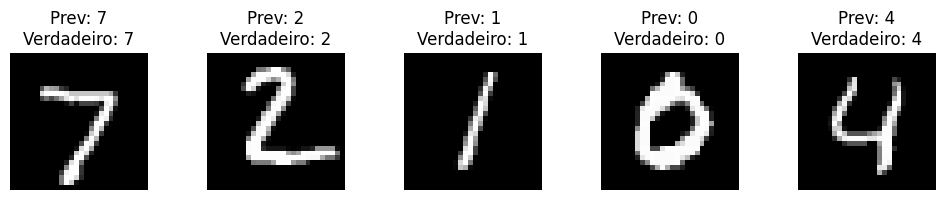

In [16]:
predictions = model.predict(x_test[:5])

plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Prev: {np.argmax(predictions[i])}\nVerdadeiro: {y_test[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()